# 04 · Optimización de hiperparámetros
**Proyecto integrador — Lector de Facturas** · Sebastián Rojas y Jesús López

El lector no entrena pesos, pero sí tiene **hiperparámetros**: decisiones de configuración que cambian el resultado. Este notebook los optimiza con el método del Workshop S5, usando **el extractor real del modelo final** (`consensus.extract`), no una copia:

1. Definir el espacio de búsqueda (hiperparámetros y rangos) y la función objetivo.
2. **Análisis de sensibilidad** de uno en uno, con el resto en el valor actual.
3. **Búsqueda aleatoria** sobre todo el espacio.
4. Modelo sustituto (Random Forest) sobre los resultados para obtener **partial dependence plots**, **ranking de importancia** e **interacciones**. Su calidad se comprueba con el R² fuera de bolsa y se contrasta con efectos medidos directamente.
5. Selección de la mejor configuración y **comparación antes/después** en una muestra de control distinta.

**Hiperparámetros optimizados**

| Grupo | Hiperparámetro | Valor actual | Rango explorado |
|---|---|---|---|
| Consenso | `primary_weight`: peso del voto de la vista principal | 1,5 | 1, 1,5, 2, 3 |
| Consenso | `vote_weight`: puntos por cada vista que coincide | 2 | 0, 1, 2, 3, 4 |
| Consenso | `fuzzy_weight`: puntos por lecturas a un carácter de distancia | 0,5 | 0, 0,25, 0,5, 1 |
| Consenso | `balance_bonus`: bono si subtotal + impuesto = total | 3 | 0, 1,5, 3, 6 |
| Etapas | `printed_improvements`, `semantic_amounts`, `document_consistency`, `structured_fields`, `observed_accounting`, `confidence_rescue` | activas | sí / no |
| Vistas OCR | `usar_pesos_best` (4 vistas `tessdata_best` y rescate), `usar_vista_espanol`, `usar_rescate_ocr` | sí | sí / no |

`accounting_improvements` queda fijo en activo: es la etapa que **impide** asumir total = subtotal cuando no se ve un impuesto, una decisión de responsabilidad que no se cambia por exactitud.

**Datos:** solo la partición `validation`, separada por hash en **optimización** (para buscar) y **control** (para medir el antes/después sin sesgo de selección), sin imágenes del test oficial. El OCR se ejecuta **una sola vez** y cada configuración se evalúa sobre esas lecturas; apagar un grupo de vistas se simula quitándolas de la lectura. El test se usa solo en `05_evaluacion.ipynb`.

> Con `USAR_DRIVE = True` se reutiliza la caché OCR de los notebooks 02 y 03.

## 1. Configuración

In [1]:
# ===== Configuración común de los notebooks 01–06 =====
# En Colab no hace falta clonar nada: se descarga el código de GitHub y se registra su commit.
USAR_CODIGO_LOCAL = False  # True si abres Jupyter dentro de un clon local del repositorio
CODIGO_LOCAL = ''          # Opcional: ruta del clon local (por defecto, la carpeta padre de notebooks/)
USAR_DRIVE = False         # True: datos, pesos, caché OCR y resultados quedan en Google Drive (los notebooks no repiten descargas ni OCR)
DESCARGAR_SI_FALTAN = True
DATOS_MANUAL = ''          # Opcional: ruta a data/raw existente en Drive o Colab
REPOSITORIO = 'Jesusl2202/Document-Scanner'
RAMA = 'main'
SEED = 42

from pathlib import Path
import os, sys, json, subprocess, shutil, hashlib, zipfile, io, urllib.request


def comando(args, cwd=None, mostrar_error=True):
    """Ejecuta un comando y muestra la salida solo si falla."""
    r = subprocess.run(list(map(str, args)), cwd=cwd, capture_output=True, text=True)
    if r.returncode:
        if mostrar_error:
            print(r.stdout[-3000:]); print(r.stderr[-3000:])
        r.check_returncode()
    return r.stdout + r.stderr


# 1) Carpeta de trabajo (fuera de Git)
if USAR_CODIGO_LOCAL:
    CODIGO = Path(CODIGO_LOCAL) if CODIGO_LOCAL else (Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())
    TRABAJO = CODIGO / 'outputs/experimentos'
elif USAR_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    TRABAJO = Path('/content/drive/MyDrive/Lector_Facturas_Experimentos')
else:
    TRABAJO = Path('/content/Lector_Facturas_Experimentos')
TRABAJO.mkdir(parents=True, exist_ok=True)
SALIDAS = TRABAJO / 'notebooks'
SALIDAS.mkdir(parents=True, exist_ok=True)

# 2) Código del repositorio: se descarga el commit exacto y se registra
if USAR_CODIGO_LOCAL:
    REVISION = {'modo': 'local', 'ruta': str(CODIGO)}
else:
    pedido = urllib.request.Request(f'https://api.github.com/repos/{REPOSITORIO}/commits/{RAMA}', headers={'User-Agent': 'lector-facturas'})
    with urllib.request.urlopen(pedido, timeout=60) as respuesta:
        commit = json.load(respuesta)['sha']
    CODIGO = TRABAJO / f'codigo_{commit[:7]}'
    if not (CODIGO / 'src/lector_facturas/consensus.py').exists():
        with urllib.request.urlopen(f'https://codeload.github.com/{REPOSITORIO}/zip/{commit}', timeout=120) as respuesta:
            blob = respuesta.read()
        with zipfile.ZipFile(io.BytesIO(blob)) as z:
            for nombre in z.namelist():
                relativo = '/'.join(nombre.split('/')[1:])
                if not relativo or nombre.endswith('/'):
                    continue
                destino = (CODIGO / relativo).resolve()
                if not destino.is_relative_to(CODIGO.resolve()):
                    raise ValueError('Ruta no permitida dentro del ZIP')
                destino.parent.mkdir(parents=True, exist_ok=True)
                destino.write_bytes(z.read(nombre))
    REVISION = {'repositorio': REPOSITORIO, 'rama': RAMA, 'commit': commit}
assert (CODIGO / 'src/lector_facturas/consensus.py').exists(), 'No se encontró el código del lector.'
RAIZ = CODIGO
print('Código:', REVISION)

# 3) Tesseract y bibliotecas
if shutil.which('apt-get') and not shutil.which('tesseract'):
    print('Instalando Tesseract...')
    comando(['apt-get', 'update', '-qq'])
    comando(['apt-get', 'install', '-y', '-qq', 'tesseract-ocr'])
assert shutil.which('tesseract'), 'No se encontró Tesseract. Usa Google Colab con CPU o instálalo en tu equipo.'
comando([sys.executable, '-m', 'pip', 'install', '-q', '-r', CODIGO / 'requirements.txt'])
sys.path.insert(0, str(CODIGO / 'src'))
for modulo in list(sys.modules):
    if modulo == 'lector_facturas' or modulo.startswith('lector_facturas.'):
        del sys.modules[modulo]

# 4) Modelo: configuración definitiva + pesos Tesseract fijados por SHA-256 (fast, best y español)
from lector_facturas import frozen_runtime
RAW_CONFIG = json.loads((CODIGO / 'configs/definitivo.json').read_text(encoding='utf-8'))
assert hasattr(frozen_runtime, 'bind_models') and RAW_CONFIG.get('observed_accounting'), (
    'El código descargado no corresponde al modelo «resumen contable» (configs/definitivo.json). '
    'Revisa REPOSITORIO y RAMA, o usa USAR_CODIGO_LOCAL=True dentro de un clon del repositorio.')
RAW_CONFIG['seed'] = SEED
CONFIG = frozen_runtime.bind_models(RAW_CONFIG, TRABAJO / 'modelos')
VISTAS_MODELO = len(CONFIG['ocr']['ensemble_views'])
print(comando(['tesseract', '--version']).splitlines()[0], f'| {VISTAS_MODELO} vistas OCR + hasta',
      CONFIG['ocr']['adaptive_rescue']['max_views'], 'de rescate')

# 5) Datos: se buscan por contenido y se descargan si faltan
candidatos = [Path(DATOS_MANUAL)] if DATOS_MANUAL else [
    Path('/content/Document-Scanner/data/raw'), TRABAJO / 'data/raw']
DATOS = next((p for p in candidatos if p.exists()), candidatos[-1])
DATOS.mkdir(parents=True, exist_ok=True)


def localizar():
    """Encuentra la raíz de SROIE y de WildReceipt por su contenido, no por el nombre de la carpeta."""
    sroie = next((p.parent.parent for p in DATOS.rglob('entities') if p.is_dir() and p.parent.name == 'train'
                  and (p.parent / 'img').exists() and (p.parent / 'box').exists()), None)
    wild = next((p.parent for p in DATOS.rglob('class_list.txt') if (p.parent / 'train.txt').exists() and (p.parent / 'test.txt').exists()), None)
    return sroie, wild


SROIE, WILD = localizar()
for nombre, ruta in [('sroie', SROIE), ('wildreceipt', WILD)]:
    if ruta is None and DESCARGAR_SI_FALTAN:
        print('Descargando', nombre, '...', flush=True)
        try:
            print(comando([sys.executable, CODIGO / 'scripts/download_data.py', nombre, '--out', DATOS], mostrar_error=False))
        except subprocess.CalledProcessError:
            print(f'No se pudo descargar {nombre}. Descárgalo a mano en {DATOS} o indica DATOS_MANUAL (ver data/raw/README.md).')
SROIE, WILD = localizar()
print('SROIE:      ', SROIE or 'NO ENCONTRADO')
print('WildReceipt:', WILD or 'NO ENCONTRADO')
assert SROIE and WILD, 'Faltan datasets: revisa data/raw/README.md.'

# 6) Manifiesto con la partición del proyecto (train / validation / test / quarantine)
from lector_facturas.datasets import prepare
FILAS = prepare(SROIE, WILD, SALIDAS / 'preparados', RAW_CONFIG)
REVISADOS = json.loads((CODIGO / 'configs/documentos_revisados.json').read_text(encoding='utf-8'))
print('Documentos en el manifiesto:', len(FILAS), '| documentos ya revisados en el desarrollo:', len(REVISADOS))

Código: {'modo': 'local', 'ruta': '/home/runner/work/Document-Scanner/Document-Scanner'}


tesseract 5.3.4 | 10 vistas OCR + hasta 2 de rescate
SROIE:       /home/runner/work/Document-Scanner/Document-Scanner/data/raw/sroie_distribution/SROIE2019
WildReceipt: /home/runner/work/Document-Scanner/Document-Scanner/data/raw/wildreceipt


Documentos en el manifiesto: 2712 | documentos ya revisados en el desarrollo: 1461


### 1.1 Librerías, parámetros y funciones
Ejecuta esta celda antes de continuar.

In [2]:
# Funciones de gráficos compartidas por los notebooks 01–06 (se repiten para que cada uno funcione solo en Colab).
import glob, re, json, types
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

AZUL, NARANJA, AQUA, GRIS = '#2a78d6', '#eb6834', '#1baf7a', '#8a8984'

FONDO, TEXTO, TEXTO2, REJILLA = '#fcfcfb', '#0b0b0b', '#52514e', '#e4e3df'

COLOR = {'sroie': AZUL, 'wildreceipt': NARANJA}

NOMBRE = {'sroie': 'SROIE', 'wildreceipt': 'WildReceipt'}

CAMPOS = ['tax_id', 'date', 'document_number', 'subtotal', 'tax', 'total']

plt.rcParams.update({
    'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'axes.edgecolor': REJILLA,
    'axes.labelcolor': TEXTO2, 'xtick.color': TEXTO2, 'ytick.color': TEXTO2, 'text.color': TEXTO,
    'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
    'grid.color': REJILLA, 'grid.linewidth': .6, 'axes.axisbelow': True, 'legend.frameon': False})

def es_num(valor, decimales=0):
    """Formato numérico en español: 1.234,5."""
    texto = f'{valor:,.{decimales}f}'
    return texto.replace(',', 'X').replace('.', ',').replace('X', '.')

def guardar(fig, carpeta, nombre):
    fig.tight_layout()
    fig.savefig(Path(carpeta) / nombre, dpi=150)
    plt.close(fig)
    print('  figura:', nombre)

def leer_csv(ruta):
    return pd.read_csv(ruta, encoding='utf-8-sig')

def fig_particiones(documentos, incidencias, manifest, salida):
    """Figura 1. Documentos por partición y dataset."""
    if manifest is not None:
        conteo = manifest.groupby(['dataset', 'split']).size().unstack(fill_value=0)
    else:
        # Sin manifiesto solo se conocen desarrollo y cuarentena.
        conteo = documentos.groupby(['dataset', 'split']).size().unstack(fill_value=0)
        cuarentena = incidencias[incidencias.split == 'quarantine'].drop_duplicates('id')
        conteo['quarantine'] = cuarentena.groupby('dataset').size().reindex(conteo.index, fill_value=0)
        print('  aviso: sin --manifest la Figura 1 no muestra el test oficial')
    columnas = {'train': ('Entrenamiento', AZUL), 'validation': ('Validación', AQUA),
                'test': ('Test oficial (reservado)', GRIS), 'quarantine': ('Cuarentena', NARANJA)}
    total = int(conteo.values.sum())
    fig, ax = plt.subplots(figsize=(8, 3.2))
    izquierda = np.zeros(len(conteo))
    etiquetas = [NOMBRE.get(d, d) for d in conteo.index]
    for clave, (texto, color) in columnas.items():
        if clave not in conteo:
            continue
        valores = conteo[clave].values
        ax.barh(etiquetas, valores, left=izquierda, color=color, label=texto,
                edgecolor=FONDO, linewidth=2, height=.55)
        for i, v in enumerate(valores):
            if v > 60:
                ax.text(izquierda[i] + v / 2, i, es_num(v), ha='center', va='center',
                        color='white', fontsize=9, fontweight='bold')
        izquierda += valores
    ax.set_xlabel('Documentos')
    ax.set_title(f'Figura 1. Partición de los {es_num(total)} documentos', loc='left')
    ax.legend(ncol=4, loc='upper center', bbox_to_anchor=(.5, -.28))
    ax.grid(axis='y', visible=False)
    ax.invert_yaxis()
    guardar(fig, salida, '01_particiones.png')
    return conteo

def fig_resolucion(documentos, salida):
    """Figura 2. Ancho vs. alto de las imágenes de desarrollo."""
    fig, ax = plt.subplots(figsize=(7, 4.6))
    for ds in ['wildreceipt', 'sroie']:
        g = documentos[documentos.dataset == ds]
        if g.empty:
            continue
        ax.scatter(g.width, g.height, s=12, alpha=.45, color=COLOR[ds], edgecolors='none',
                   label=f'{NOMBRE[ds]} (mediana {int(g.width.median())}×{int(g.height.median())} px)')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlabel('Ancho (px, escala log)')
    ax.set_ylabel('Alto (px, escala log)')
    ax.set_title('Figura 2. Resolución de las imágenes de desarrollo', loc='left')
    ax.legend(loc='upper left')
    guardar(fig, salida, '02_resolucion.png')

def fig_regiones(documentos, salida):
    """Figura 3. Regiones de texto anotadas por documento."""
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    bins = np.arange(0, documentos.regions.max() + 6, 6)
    for ds in ['sroie', 'wildreceipt']:
        g = documentos[documentos.dataset == ds].regions
        if g.empty:
            continue
        ax.hist(g, bins=bins, alpha=.6, color=COLOR[ds], edgecolor=FONDO, linewidth=1,
                label=f'{NOMBRE[ds]} (mediana {int(g.median())})')
        ax.axvline(g.median(), color=COLOR[ds], ls='--', lw=1.5)
    ax.set_xlabel('Regiones de texto anotadas por documento')
    ax.set_ylabel('Documentos')
    ax.set_title('Figura 3. Cantidad de texto por recibo', loc='left')
    ax.legend()
    guardar(fig, salida, '03_regiones.png')

def fig_cobertura(cobertura, salida):
    """Figura 4. Porcentaje de documentos con etiqueta utilizable por campo."""
    tabla = cobertura.pivot(index='dataset', columns='field', values='coverage').reindex(columns=CAMPOS)
    mapa = LinearSegmentedColormap.from_list('azules', ['#f1f0ec', '#cfe0f6', '#7fb0ea', AZUL, '#0d3f80'])
    fig, ax = plt.subplots(figsize=(8, 1.3 + .65 * len(tabla)))
    ax.imshow(tabla.values, cmap=mapa, vmin=0, vmax=1, aspect='auto')
    ax.grid(False)
    ax.set_xticks(range(len(CAMPOS)), CAMPOS)
    ax.set_yticks(range(len(tabla)), [NOMBRE.get(d, d) for d in tabla.index])
    for i in range(tabla.shape[0]):
        for j in range(tabla.shape[1]):
            v = tabla.values[i, j]
            ax.text(j, i, f'{es_num(100 * v)}%', ha='center', va='center',
                    color='white' if v > .55 else TEXTO, fontweight='bold')
    for borde in ax.spines.values():
        borde.set_visible(False)
    ax.set_title('Figura 4. Campos con etiqueta utilizable (documentos de desarrollo)', loc='left')
    guardar(fig, salida, '04_cobertura.png')

def fig_clases_lineas(texto, salida):
    """Figura 5. Desbalance de clases por línea (datos del clasificador de Semana 3)."""
    conteo = pd.Series({k.strip(): int(v) for k, v in (p.split('=') for p in texto.split(','))}).sort_values()
    total = conteo.sum()
    fig, ax = plt.subplots(figsize=(7.5, 3.2))
    ax.barh(conteo.index, conteo.values, height=.55,
            color=[GRIS if k.lower().startswith('otro') else AZUL for k in conteo.index])
    for i, v in enumerate(conteo.values):
        ax.text(v * 1.08, i, f'{es_num(v)} ({es_num(100 * v / total, 1)}%)', va='center', color=TEXTO2, fontsize=9)
    ax.set_xscale('log')
    ax.set_xlim(conteo.min() / 2, conteo.max() * 4)
    ax.set_xlabel('Líneas OCR en entrenamiento (escala log)')
    ax.grid(axis='y', visible=False)
    ax.set_title('Figura 5. Desbalance de clases por línea', loc='left')
    guardar(fig, salida, '05_desbalance_lineas.png')

def fig_cer(cer, documentos, salida):
    """Figura 6. CER del OCR frente al tamaño de la imagen."""
    datos = cer.merge(documentos, on=['id', 'dataset'])
    if datos.empty:
        print('  aviso: los documentos de cer.csv no están en documents.csv; se omite la Figura 6')
        return None
    datos['mpx'] = datos.width * datos.height / 1e6
    rho = datos[['cer', 'mpx']].corr(method='spearman').iloc[0, 1]
    fig, ax = plt.subplots(figsize=(7, 4.2))
    for ds in ['sroie', 'wildreceipt']:
        g = datos[datos.dataset == ds]
        if g.empty:
            continue
        ax.scatter(g.mpx, g.cer, s=46, color=COLOR[ds], edgecolors=FONDO, linewidths=1.5,
                   label=f'{NOMBRE[ds]} (CER mediano {es_num(g.cer.median(), 2)})')
    ax.set_xscale('log')
    ax.set_xlabel('Tamaño de la imagen (megapíxeles, escala log)')
    ax.set_ylabel('CER del OCR')
    ax.set_title(f'Figura 6. Imágenes más pequeñas se leen peor (Spearman ρ = {es_num(rho, 2)})', loc='left')
    ax.legend()
    guardar(fig, salida, '06_cer_vs_resolucion.png')
    return datos

def tipo_error(errores):
    """Clasifica cada campo evaluado en correcto, omitido o valor incorrecto."""
    vacio = errores.predicted.isna() | (errores.predicted.astype(str).str.strip() == '')
    return np.where(errores.correct == 1, 'Correcto',
                    np.where(vacio, 'Omitido (no extrajo nada)', 'Valor incorrecto'))

def fig_errores(errores, salida):
    """Figura 7. Resultado por campo: correcto, valor incorrecto u omitido."""
    errores = errores.assign(tipo=tipo_error(errores))
    orden = ['Correcto', 'Valor incorrecto', 'Omitido (no extrajo nada)']
    tabla = errores.groupby(['dataset', 'field', 'tipo']).size().unstack(fill_value=0).reindex(columns=orden, fill_value=0)
    tabla.index = [f'{NOMBRE.get(d, d)} · {c}' for d, c in tabla.index]
    documentos = errores.id.nunique()
    fig, ax = plt.subplots(figsize=(8, 1.4 + .4 * len(tabla)))
    izquierda = np.zeros(len(tabla))
    for col, color in zip(orden, [AQUA, NARANJA, '#b9b8b2']):
        valores = tabla[col].values
        ax.barh(tabla.index, valores, left=izquierda, color=color, label=col, edgecolor=FONDO, linewidth=2, height=.6)
        for i, v in enumerate(valores):
            if v >= 2:
                ax.text(izquierda[i] + v / 2, i, str(v), ha='center', va='center', fontsize=9,
                        color=TEXTO if col.startswith('Omitido') else 'white')
        izquierda += valores
    ax.invert_yaxis()
    ax.set_xlabel('Campos anotados')
    ax.grid(axis='y', visible=False)
    ax.set_title(f'Figura 7. Resultado por campo ({documentos} documentos)', loc='left')
    ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(.5, -.2))
    guardar(fig, salida, '07_errores_linea_base.png')
    return errores

def fig_correlaciones(documentos, salida):
    """Figura 8. Correlación de Spearman entre variables de la imagen, por dataset."""
    variables = {'width': 'Ancho', 'height': 'Alto', 'mpx': 'Megapíxeles', 'regions': 'Regiones', 'aspect': 'Alto/ancho'}
    mapa = LinearSegmentedColormap.from_list('div', [NARANJA, '#f6c3ad', '#f1f0ec', '#a9c8f0', AZUL])
    bases = [d for d in ['sroie', 'wildreceipt'] if d in set(documentos.dataset)]
    fig, ejes = plt.subplots(1, len(bases), figsize=(4.5 * len(bases), 3.8), squeeze=False)
    matrices = {}
    for ax, ds in zip(ejes[0], bases):
        m = documentos[documentos.dataset == ds][list(variables)].corr(method='spearman')
        matrices[ds] = m
        ax.imshow(m.values, cmap=mapa, vmin=-1, vmax=1)
        ax.grid(False)
        ax.set_xticks(range(len(variables)), variables.values(), rotation=35, ha='right')
        ax.set_yticks(range(len(variables)), variables.values())
        for i in range(len(variables)):
            for j in range(len(variables)):
                v = m.values[i, j]
                ax.text(j, i, es_num(v, 2), ha='center', va='center', fontsize=8,
                        color='white' if abs(v) > .6 else TEXTO)
        ax.set_title(NOMBRE[ds])
        for borde in ax.spines.values():
            borde.set_visible(False)
    fig.suptitle('Figura 8. Correlación de Spearman entre variables de la imagen', x=.02, ha='left', fontweight='bold')
    guardar(fig, salida, '08_correlaciones.png')
    return matrices

PATRONES_FECHA = {'99/99/9999': 'dd/mm/aaaa', '99-99-99': 'dd-mm-aa', '99-99-9999': 'dd-mm-aaaa',
                  '99/99/99': 'dd/mm/aa', '99 A 9999': 'dd MES aaaa'}

def patron(fecha):
    """Convierte '25/12/2018' en '99/99/9999' y 'MAR' en 'A' para agrupar formatos."""
    return re.sub(r'\d', '9', re.sub(r'[A-Za-z]+', 'A', fecha))

def fig_formatos_fecha(carpeta, salida):
    """Figura 9. Formatos de fecha en las etiquetas de entrenamiento de SROIE."""
    fechas = []
    for archivo in sorted(glob.glob(str(Path(carpeta) / '*'))):
        if not archivo.endswith(('.json', '.txt')):
            continue
        try:
            fechas.append(str(json.loads(Path(archivo).read_text(encoding='utf-8-sig')).get('date', '')).strip())
        except (json.JSONDecodeError, UnicodeDecodeError):
            print('  aviso: no se pudo leer', archivo)
    if not fechas:
        print('  aviso: no hay etiquetas en --sroie-keys; se omite la Figura 9')
        return None
    formatos = Counter(patron(f) for f in fechas)
    ambiguas = 0
    for f in fechas:
        m = re.fullmatch(r'\(?(\d{1,2})[/.\-](\d{1,2})[/.\-](\d{2,4})\)?', f)
        if m and int(m.group(1)) <= 12 and int(m.group(2)) <= 12 and m.group(1) != m.group(2):
            ambiguas += 1
    agrupado = Counter()
    for p, n in formatos.items():
        agrupado[PATRONES_FECHA.get(p, 'otros')] += n
    otros = len([p for p in formatos if p not in PATRONES_FECHA])
    orden = [v for v in PATRONES_FECHA.values() if agrupado[v]] + (['otros'] if agrupado['otros'] else [])
    orden = orden[::-1]
    etiquetas = [f'Otros {otros} formatos' if o == 'otros' else o for o in orden]
    valores = [agrupado[o] for o in orden]
    n = len(fechas)
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.barh(etiquetas, valores, color=AZUL, height=.55)
    ax.grid(axis='y', visible=False)
    for i, v in enumerate(valores):
        ax.text(v + n * .006, i, f'{v} ({es_num(100 * v / n, 1)}%)', va='center', color=TEXTO2, fontsize=9)
    ax.set_xlim(0, max(valores) * 1.2)
    ax.set_xlabel(f'Recibos de entrenamiento de SROIE (n = {n})')
    ax.set_title('Figura 9. Formatos de fecha en las etiquetas de SROIE', loc='left')
    guardar(fig, salida, '09_formatos_fecha.png')
    return {'recibos': n, 'formatos_distintos': len(formatos), 'fechas_dia_mes_ambiguas': ambiguas,
            'porcentaje_ambiguas': round(100 * ambiguas / n, 1),
            'formatos': dict(formatos.most_common())}

def tablas(documentos, salida):
    """Estadísticas descriptivas y outliers (criterio 1,5 × IQR) por dataset."""
    variables = ['width', 'height', 'aspect', 'mpx', 'regions']
    describe = documentos.groupby('dataset')[variables].describe(percentiles=[.25, .5, .75]).T.round(2)
    describe.to_csv(Path(salida) / 'estadisticas_descriptivas.csv', encoding='utf-8-sig')
    filas = []
    for ds, g in documentos.groupby('dataset'):
        for v in ['width', 'height', 'mpx', 'regions']:
            q1, q3 = g[v].quantile([.25, .75])
            limite_bajo, limite_alto = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
            n = int(((g[v] < limite_bajo) | (g[v] > limite_alto)).sum())
            filas.append({'dataset': ds, 'variable': v, 'outliers': n, 'documentos': len(g),
                          'porcentaje': round(100 * n / len(g), 1),
                          'limite_inferior': round(limite_bajo, 2), 'limite_superior': round(limite_alto, 2)})
    outliers = pd.DataFrame(filas)
    outliers.to_csv(Path(salida) / 'outliers_iqr.csv', index=False, encoding='utf-8-sig')
    print('  tablas: estadisticas_descriptivas.csv, outliers_iqr.csv')
    return describe, outliers

F = types.SimpleNamespace(AZUL=AZUL, NARANJA=NARANJA, AQUA=AQUA, GRIS=GRIS, FONDO=FONDO, TEXTO=TEXTO, TEXTO2=TEXTO2, REJILLA=REJILLA, COLOR=COLOR, NOMBRE=NOMBRE, CAMPOS=CAMPOS, es_num=es_num, guardar=guardar, leer_csv=leer_csv, fig_particiones=fig_particiones, fig_resolucion=fig_resolucion, fig_regiones=fig_regiones, fig_cobertura=fig_cobertura, fig_clases_lineas=fig_clases_lineas, fig_cer=fig_cer, tipo_error=tipo_error, fig_errores=fig_errores, fig_correlaciones=fig_correlaciones, PATRONES_FECHA=PATRONES_FECHA, patron=patron, fig_formatos_fecha=fig_formatos_fecha, tablas=tablas)

In [3]:
import json, re, hashlib, warnings, copy, time, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as Img, Markdown
warnings.filterwarnings('ignore', category=FutureWarning)
%matplotlib inline
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
from lector_facturas import consensus
from lector_facturas.common import FIELDS, normalize, write_json, write_jsonl
from lector_facturas.ocr import transcribe
from lector_facturas.evaluation import evaluate
from lector_facturas.experiments import bootstrap_delta, validation_samples
N_OPT = 30          # documentos por dataset para optimizar (los mismos del notebook 03: reutiliza caché)
N_CONTROL = 20      # documentos por dataset para el control antes/después
N_BUSQUEDA = 80     # configuraciones de la búsqueda aleatoria (además de la actual)
N_DOCS_EQUIVALENCIA = 20
CACHE = SALIDAS / 'cache_ocr'
OPT = SALIDAS / 'optimizacion'; OPT.mkdir(parents=True, exist_ok=True)
FIG = OPT / 'figuras'; FIG.mkdir(parents=True, exist_ok=True)

## 2. Muestras de optimización y control
`experiments.validation_samples`: solo validación, disjuntas por hash y sin duplicados del test oficial. Antes de leer nada se guarda el plan (muestras, semilla, configuración y hash del código).

In [4]:
opt, control = validation_samples(FILAS, N_OPT, N_CONTROL, SEED)
assert not {r['sha256'] for r in opt} & {r['sha256'] for r in control}, 'Optimización y control comparten imágenes'
assert all(r['split'] == 'validation' for r in opt + control), 'Solo validación'
write_jsonl(OPT / 'optimizacion.jsonl', opt); write_jsonl(OPT / 'control.jsonl', control)
write_json(OPT / 'plan.json', {'semilla': SEED, 'n_opt': N_OPT, 'n_control': N_CONTROL, 'n_busqueda': N_BUSQUEDA,
                               'revision_codigo': REVISION, 'configuracion': RAW_CONFIG,
                               'codigo_sha256': {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted((RAIZ / 'src/lector_facturas').glob('*.py'))},
                               'nota': 'Plan fijado antes de leer el OCR. El test oficial no participa.'})
revisados = set(REVISADOS) | set(REVISADOS.values())
display(pd.DataFrame({'optimización': Counter(r['dataset'] for r in opt), 'control': Counter(r['dataset'] for r in control)}))
print('Documentos ya revisados en el desarrollo:', sum(r['id'] in revisados or r['sha256'] in revisados for r in opt + control),
      'de', len(opt + control), '(el control es disjunto de la optimización, pero no inédito).')

,optimización,control
sroie,30,20
wildreceipt,30,20


Documentos ya revisados en el desarrollo: 56 de 100 (el control es disjunto de la optimización, pero no inédito).


## 3. Lectura OCR (una sola vez)
Se leen todas las vistas del modelo final y se guardan en caché. Si 02 y 03 ya se ejecutaron con `USAR_DRIVE = True`, sale de caché.

In [5]:
LECTURAS, ERRORES_OCR = {}, {}
inicio = time.perf_counter()
todas = opt + control
for i, fila in enumerate(todas, 1):
    try:
        LECTURAS[fila['id']] = transcribe(fila['image'], CONFIG['ocr'], CACHE)
    except Exception as exc:
        ERRORES_OCR[fila['id']] = str(exc)
    if i % 10 == 0 or i == len(todas):
        print(f'{i}/{len(todas)} · {time.perf_counter() - inicio:.0f} s', flush=True)
print('Errores de OCR:', len(ERRORES_OCR), '(cuentan como fallo en todas las configuraciones)')

10/100 · 89 s


20/100 · 169 s


30/100 · 257 s


40/100 · 311 s


50/100 · 367 s


...

70/100 · 506 s


80/100 · 599 s


90/100 · 651 s


100/100 · 724 s


Errores de OCR: 0 (cuentan como fallo en todas las configuraciones)


## 4. Espacio de búsqueda y función objetivo
- **Objetivo principal:** exactitud **macro** por combinación dataset/campo (SROIE aporta fecha y total; WildReceipt fecha, subtotal, impuesto y total). Así un campo con mucho soporte no tapa a uno débil.
- **Desempates:** peor combinación dataset/campo, exactitud global (micro), menos cambios respecto a la configuración actual y menor costo de OCR.
- **Costo:** mediana por documento de los segundos de OCR de las vistas usadas (las vistas se leen en paralelo, así que es una cota superior).

La celda comprueba primero que, con los valores actuales, el arnés reproduce exactamente al lector entregado.

In [6]:
PARAMS_CONSENSO = ['primary_weight', 'vote_weight', 'fuzzy_weight', 'balance_bonus']
ETAPAS_BUSQUEDA = ['printed_improvements', 'semantic_amounts', 'document_consistency', 'structured_fields',
                   'observed_accounting', 'confidence_rescue']
VISTAS_BUSQUEDA = ['usar_pesos_best', 'usar_vista_espanol', 'usar_rescate_ocr']
ESPACIO = {'primary_weight': [1.0, 1.5, 2.0, 3.0], 'vote_weight': [0.0, 1.0, 2.0, 3.0, 4.0],
           'fuzzy_weight': [0.0, 0.25, 0.5, 1.0], 'balance_bonus': [0.0, 1.5, 3.0, 6.0],
           **{e: [True, False] for e in ETAPAS_BUSQUEDA}, **{v: [True, False] for v in VISTAS_BUSQUEDA}}
PARAMS = list(ESPACIO)
_consenso = dict(primary_weight=1.5, vote_weight=2.0, fuzzy_weight=0.5, balance_bonus=3.0)
_consenso.update(CONFIG.get('consensus_parameters', {}))
DEFECTO = {**_consenso, **{e: bool(CONFIG.get(e)) for e in ETAPAS_BUSQUEDA}, **{v: True for v in VISTAS_BUSQUEDA}}


def usa_vista(vista, hp):
    """Decide si una vista leída participa en la configuración hp."""
    o = vista['options']
    if not hp['usar_pesos_best'] and Path(o.get('tessdata_dir', '')).name == 'best':
        return False   # incluye el rescate, que también usa pesos best
    if not hp['usar_vista_espanol'] and '+spa' in o.get('language', ''):
        return False
    if not hp['usar_rescate_ocr'] and vista.get('rescue'):
        return False
    return True


def filtrar(ocr_resultado, hp):
    elegidas = [v for v in ocr_resultado['views'] if usa_vista(v, hp)]
    principal = next((v for v in elegidas if consensus.is_primary(v)), elegidas[0])
    return dict(principal, views=elegidas)


def config_de(hp):
    cfg = dict(CONFIG, consensus_parameters={k: float(hp[k]) for k in PARAMS_CONSENSO})
    cfg.update({e: bool(hp[e]) for e in ETAPAS_BUSQUEDA})
    return cfg


def predecir(hp, filas):
    cfg, salida = config_de(hp), {}
    for fila in filas:
        o = LECTURAS.get(fila['id'])
        try:
            if o is None:
                raise ValueError(ERRORES_OCR.get(fila['id'], 'sin OCR'))
            salida[fila['id']] = {'status': 'ok', **consensus.extract(filtrar(o, hp), cfg)}
        except Exception as exc:
            salida[fila['id']] = {'status': 'error', 'error': str(exc), 'fields': {}, 'alerts': []}
    return salida


SEGUNDOS = {doc: [(v, v.get('ocr_seconds', 0)) for v in o['views']] for doc, o in LECTURAS.items()}
_costos = {}
def costo(hp):
    clave = tuple(hp[v] for v in VISTAS_BUSQUEDA)
    if clave not in _costos:
        _costos[clave] = float(np.median([sum(s for v, s in vistas if usa_vista(v, hp)) for vistas in SEGUNDOS.values()])) if SEGUNDOS else np.nan
    return _costos[clave]


def objetivo(hp, filas):
    pred, grupos = predecir(hp, filas), {}
    for fila in filas:
        p = pred[fila['id']]
        for f in FIELDS:
            oro = fila['gold'][f]
            if oro['status'] not in ('annotated', 'absent'):
                continue
            par = grupos.setdefault(f"{fila['dataset']}/{f}", [0, 0]); par[1] += 1
            par[0] += int(p['status'] == 'ok' and normalize(f, p['fields'].get(f), CONFIG['normalization']) == normalize(f, oro['value'], CONFIG['normalization']))
    valores = [a / n for a, n in grupos.values() if n]
    return {'exactitud_macro': float(np.mean(valores)), 'peor_campo': float(min(valores)),
            'exactitud_global': sum(a for a, _ in grupos.values()) / sum(n for _, n in grupos.values()),
            'campos': sum(n for _, n in grupos.values()), 'segundos_ocr': costo(hp),
            **{f'grupo:{g}': a / n for g, (a, n) in grupos.items()}}


# Verificación: con los valores actuales el arnés es idéntico al lector entregado.
distintos = 0
for fila in opt[:N_DOCS_EQUIVALENCIA]:
    if fila['id'] in LECTURAS:
        distintos += int(consensus.extract(LECTURAS[fila['id']], CONFIG)['fields'] != predecir(DEFECTO, [fila])[fila['id']]['fields'])
assert distintos == 0, 'El arnés no reproduce al lector entregado'
print('OK: con los valores actuales el arnés reproduce exactamente a consensus.extract.')
BASE = objetivo(DEFECTO, opt)
print(f"Configuración actual en optimización: macro {BASE['exactitud_macro']:.1%} · global {BASE['exactitud_global']:.1%} · "
      f"peor campo {BASE['peor_campo']:.1%} · {BASE['segundos_ocr']:.1f} s de OCR por documento")

OK: con los valores actuales el arnés reproduce exactamente a consensus.extract.


Configuración actual en optimización: macro 73.5% · global 74.7% · peor campo 60.0% · 11.6 s de OCR por documento


## 5. Análisis de sensibilidad (uno a la vez)
Se cambia un hiperparámetro por vez, con los demás en su valor actual.

In [7]:
sens = []
for param, valores in ESPACIO.items():
    for v in valores:
        r = objetivo(dict(DEFECTO, **{param: v}), opt)
        sens.append({'hiperparámetro': param, 'valor': str(v), 'actual': v == DEFECTO[param],
                     **{k: r[k] for k in ('exactitud_macro', 'exactitud_global', 'peor_campo', 'segundos_ocr')}})
sens = pd.DataFrame(sens)
sens['cambio_pp'] = 100 * (sens.exactitud_macro - BASE['exactitud_macro'])
sens.to_csv(OPT / 'sensibilidad.csv', index=False, encoding='utf-8-sig')
resumen_sens = sens.groupby('hiperparámetro').agg(min_pp=('cambio_pp', 'min'), max_pp=('cambio_pp', 'max'))
resumen_sens['rango_pp'] = resumen_sens.max_pp - resumen_sens.min_pp
display(resumen_sens.sort_values('rango_pp', ascending=False).round(2))

,min_pp,max_pp,rango_pp
hiperparámetro,,,
vote_weight,-6.45,1.11,7.56
usar_pesos_best,-3.01,0.00,3.01
observed_accounting,-1.39,0.00,1.39
fuzzy_weight,0.00,1.11,1.11
structured_fields,-0.72,0.00,0.72
primary_weight,0.00,0.67,0.67
semantic_amounts,0.00,0.56,0.56
usar_rescate_ocr,-0.17,0.00,0.17
balance_bonus,0.00,0.00,0.00


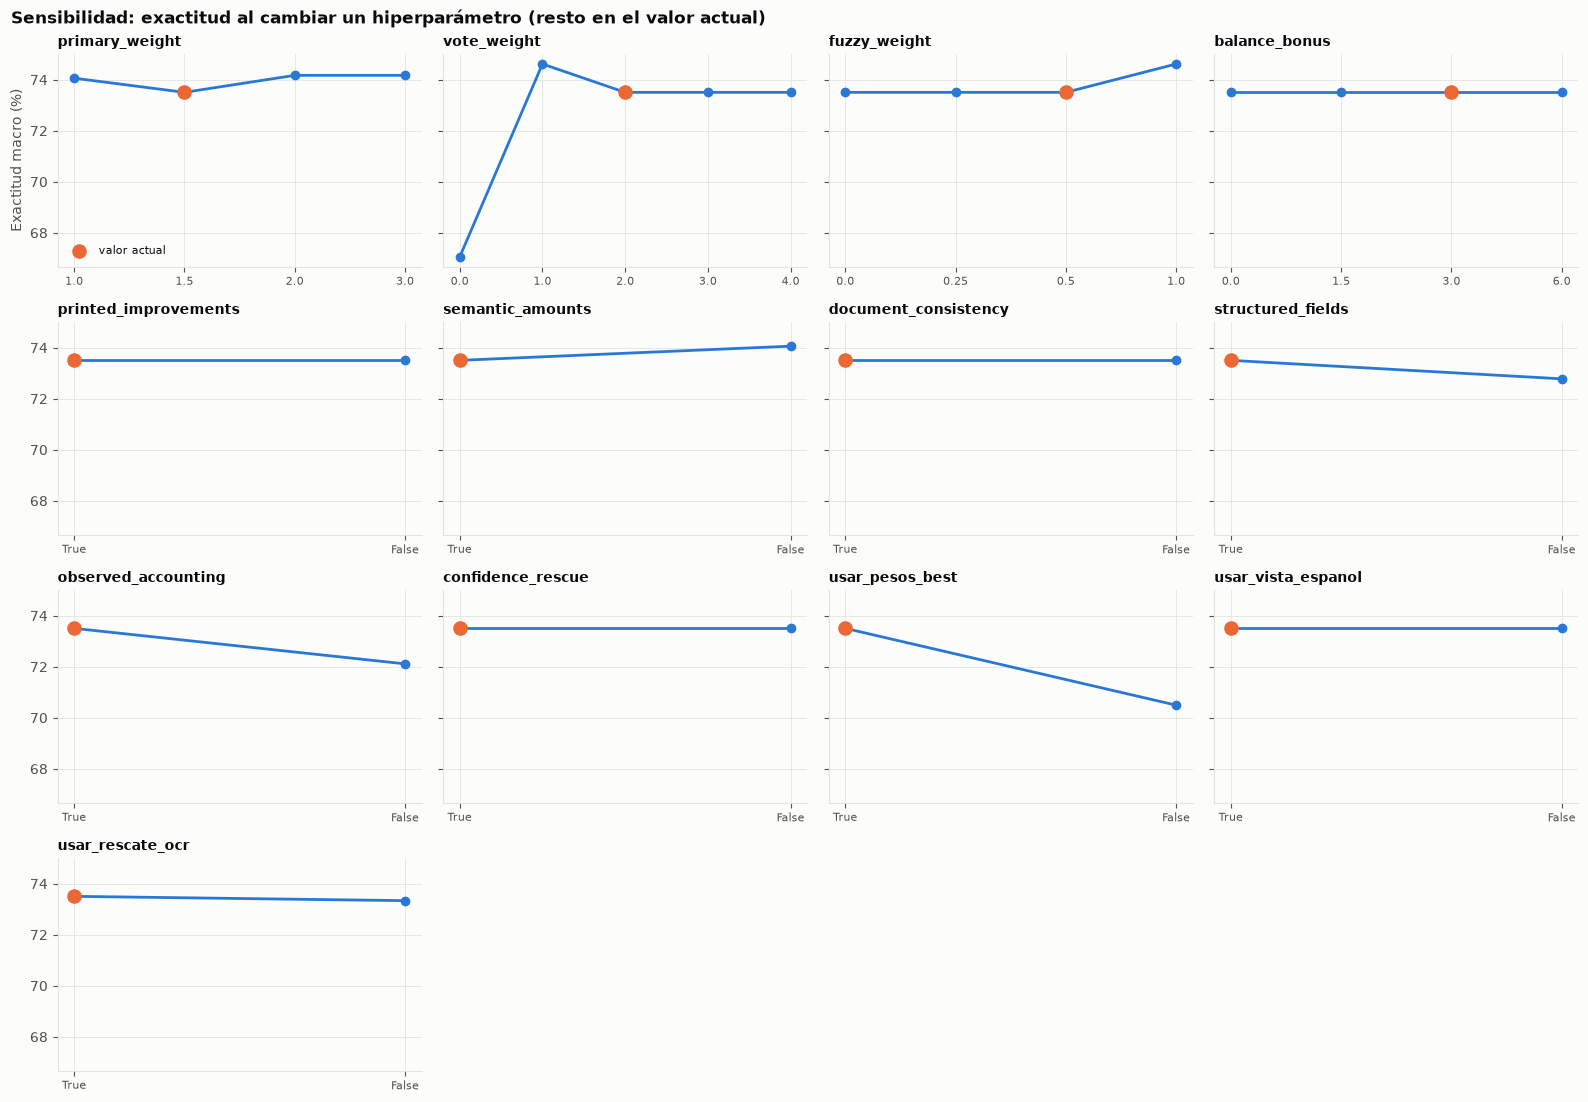

In [8]:
columnas = 4
filas_g = int(np.ceil(len(PARAMS) / columnas))
fig, ejes = plt.subplots(filas_g, columnas, figsize=(4 * columnas, 2.8 * filas_g), sharey=True)
for ax, param in zip(ejes.flat, PARAMS):
    g = sens[sens['hiperparámetro'] == param]
    ax.plot(range(len(g)), 100 * g.exactitud_macro, marker='o', color=F.AZUL, lw=2)
    actual = int(np.argmax(g.actual.values))
    ax.scatter([actual], [100 * g.exactitud_macro.iloc[actual]], s=90, color=F.NARANJA, zorder=3, label='valor actual')
    ax.set_xticks(range(len(g)), g.valor, fontsize=8)
    ax.set_title(param, fontsize=10, loc='left')
for ax in list(ejes.flat)[len(PARAMS):]:
    ax.axis('off')
ejes.flat[0].set_ylabel('Exactitud macro (%)'); ejes.flat[0].legend(fontsize=8)
fig.suptitle('Sensibilidad: exactitud al cambiar un hiperparámetro (resto en el valor actual)', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); fig.savefig(FIG / 'sensibilidad.png', dpi=150); plt.show()

## 6. Búsqueda aleatoria
Configuraciones muestreadas de manera uniforme en todo el espacio (semilla fija). Se incluye la configuración actual.

In [9]:
rng = random.Random(SEED)
configs, vistas_cfg = [dict(DEFECTO)], {json.dumps(DEFECTO, sort_keys=True)}
total_espacio = int(np.prod([len(v) for v in ESPACIO.values()]))
while len(configs) < min(N_BUSQUEDA + 1, total_espacio):
    cfg = {k: rng.choice(v) for k, v in ESPACIO.items()}
    clave = json.dumps(cfg, sort_keys=True)
    if clave not in vistas_cfg:
        vistas_cfg.add(clave); configs.append(cfg)
inicio = time.perf_counter()
busqueda = []
for i, cfg in enumerate(configs, 1):
    busqueda.append(dict(cfg, **objetivo(cfg, opt)))
    if i % 20 == 0 or i == len(configs):
        print(f'{i}/{len(configs)} configuraciones · {time.perf_counter() - inicio:.0f} s', flush=True)
busqueda = pd.DataFrame(busqueda)
busqueda['cambios'] = [sum(str(fila[p]) != str(DEFECTO[p]) for p in PARAMS) for _, fila in busqueda.iterrows()]
busqueda.to_csv(OPT / 'busqueda_aleatoria.csv', index=False, encoding='utf-8-sig')
print(f'Espacio total: {total_espacio:,} combinaciones; evaluadas {len(busqueda)}.')
display(busqueda.sort_values(['exactitud_macro', 'peor_campo', 'exactitud_global'], ascending=False).head(10)
        [PARAMS + ['exactitud_macro', 'peor_campo', 'exactitud_global', 'segundos_ocr', 'cambios']].round(3))

20/81 configuraciones · 160 s


40/81 configuraciones · 282 s


60/81 configuraciones · 406 s


80/81 configuraciones · 528 s


81/81 configuraciones · 540 s


Espacio total: 163,840 combinaciones; evaluadas 81.


,primary_weight,vote_weight,fuzzy_weight,balance_bonus,printed_improvements,semantic_amounts,document_consistency,structured_fields,observed_accounting,confidence_rescue,usar_pesos_best,usar_vista_espanol,usar_rescate_ocr,exactitud_macro,peor_campo,exactitud_global,segundos_ocr,cambios
55,2.0,2.0,1.00,0.0,True,False,True,False,True,True,True,False,True,0.744,0.60,0.760,10.461,6
19,3.0,4.0,0.25,0.0,True,True,True,True,True,False,True,True,True,0.742,0.64,0.753,11.631,5
65,1.0,2.0,1.00,6.0,False,True,False,True,True,False,True,False,True,0.741,0.60,0.753,10.461,7
17,1.5,1.0,1.00,6.0,False,True,False,True,True,False,True,False,False,0.740,0.64,0.753,9.468,8
29,2.0,2.0,1.00,0.0,False,True,False,True,False,True,True,False,False,0.740,0.64,0.753,9.468,8
0,1.5,2.0,0.50,3.0,True,True,True,True,True,True,True,True,True,0.735,0.60,0.747,11.631,0
13,1.0,2.0,0.00,1.5,True,True,True,True,True,True,True,False,True,0.735,0.60,0.747,10.461,4
32,1.5,4.0,1.00,1.5,True,False,False,True,True,False,True,True,True,0.735,0.60,0.747,11.631,6
41,1.0,3.0,0.00,0.0,False,True,True,True,True,True,True,True,True,0.735,0.60,0.747,11.631,5
26,1.5,1.0,1.00,0.0,True,False,False,True,False,True,True,False,True,0.734,0.64,0.747,10.461,7


## 7. Partial dependence plots
Se ajusta un Random Forest que predice la exactitud macro a partir de los hiperparámetros (modelo sustituto). Cada curva muestra el efecto promedio de un hiperparámetro cuando los demás varían. Primero se revisa que el sustituto explique bien los resultados (R² fuera de bolsa): si es bajo, los PDP solo se usan como orientación y manda el efecto medido directamente (secciones 5 y 8).

R² fuera de bolsa del sustituto: 0.781 (aceptable)


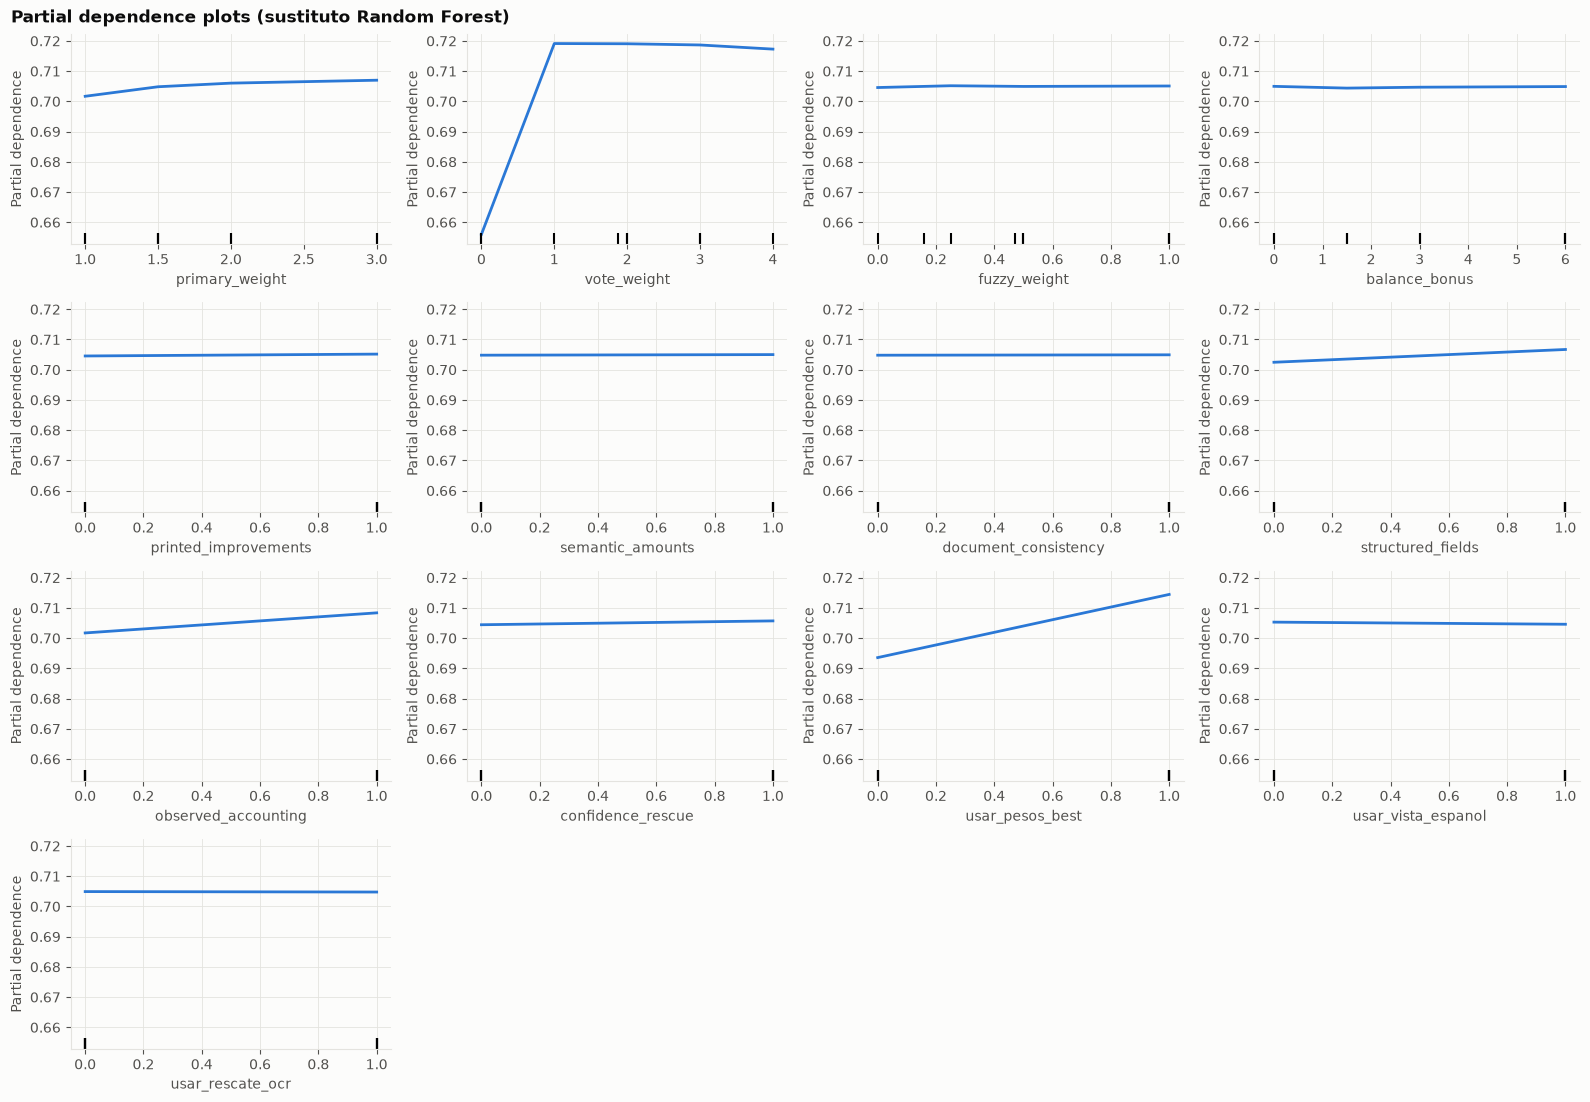

In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
X = busqueda[PARAMS].astype(float)
y = busqueda['exactitud_macro']
sustituto = RandomForestRegressor(n_estimators=400, min_samples_leaf=3, oob_score=True, random_state=SEED, n_jobs=-1).fit(X, y)
R2_OOB = sustituto.oob_score_
print(f'R² fuera de bolsa del sustituto: {R2_OOB:.3f}', '(aceptable)' if R2_OOB >= .5 else '(bajo: usar los PDP solo como orientación)')
variables = [p for p in PARAMS if X[p].nunique() > 1]
fig, ax = plt.subplots(int(np.ceil(len(variables) / columnas)), columnas, figsize=(4 * columnas, 2.8 * int(np.ceil(len(variables) / columnas))))
PartialDependenceDisplay.from_estimator(sustituto, X, variables, ax=ax.flat[:len(variables)], grid_resolution=10,
                                        line_kw={'color': F.AZUL, 'lw': 2})
for a in list(ax.flat)[len(variables):]:
    a.axis('off')
fig.suptitle('Partial dependence plots (sustituto Random Forest)', x=.01, ha='left', fontweight='bold')
plt.tight_layout(); fig.savefig(FIG / 'pdp.png', dpi=150); plt.show()

## 8. Ranking de importancia
Tres medidas que deberían coincidir:
- **Permutación** sobre el sustituto: cuánto empeora su predicción al desordenar un hiperparámetro.
- **Efecto principal** en la búsqueda: diferencia entre la mejor y la peor exactitud promedio por valor del hiperparámetro (sin sustituto).
- **Rango de sensibilidad** de la sección 5.

,permutación,permutación_std,efecto_principal_pp,rango_sensibilidad_pp,ranking
vote_weight,1.4239,0.2388,6.7492,7.5604,1
usar_pesos_best,0.2845,0.0304,1.9032,3.0097,2
observed_accounting,0.0429,0.0068,1.7787,1.3913,3
structured_fields,0.0327,0.0135,0.2078,0.7246,4
primary_weight,0.0235,0.0067,1.4016,0.6667,5
confidence_rescue,0.0159,0.0081,1.4550,0.0000,6
usar_rescate_ocr,0.0061,0.0036,0.3141,0.1691,7
balance_bonus,0.0054,0.0014,1.9693,0.0000,8
fuzzy_weight,0.0048,0.0019,2.1267,1.1111,9
document_consistency,0.0046,0.0022,0.1548,0.0000,10


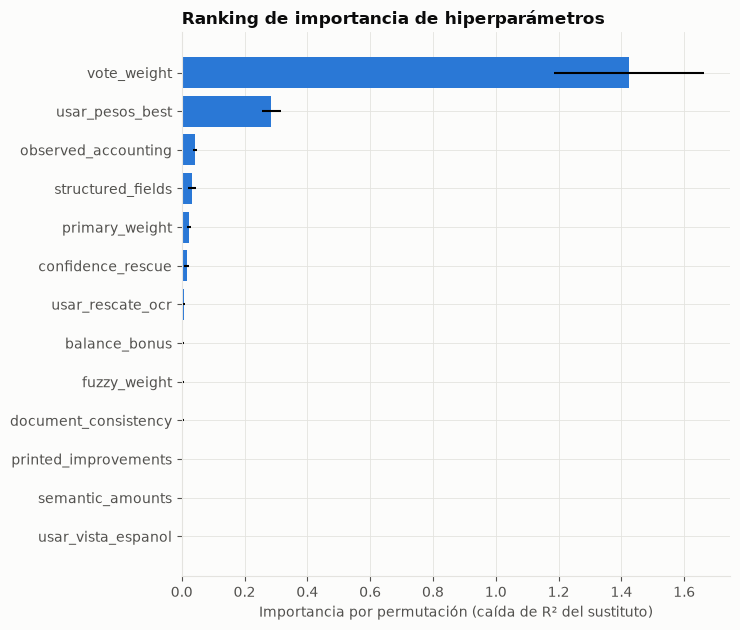

In [11]:
perm = permutation_importance(sustituto, X, y, n_repeats=20, random_state=SEED, n_jobs=-1)
efecto = {p: busqueda.groupby(p).exactitud_macro.mean().pipe(lambda s: s.max() - s.min()) for p in PARAMS}
importancia = pd.DataFrame({'permutación': perm.importances_mean, 'permutación_std': perm.importances_std,
                            'efecto_principal_pp': [100 * efecto[p] for p in PARAMS],
                            'rango_sensibilidad_pp': resumen_sens.loc[PARAMS, 'rango_pp'].values}, index=PARAMS)
importancia = importancia.sort_values('permutación', ascending=False)
importancia['ranking'] = range(1, len(importancia) + 1)
importancia.to_csv(OPT / 'importancia.csv', encoding='utf-8-sig')
display(importancia.round(4))
fig, ax = plt.subplots(figsize=(7.5, 0.4 * len(importancia) + 1.2))
ax.barh(importancia.index, importancia['permutación'], xerr=importancia['permutación_std'], color=F.AZUL)
ax.invert_yaxis(); ax.set_xlabel('Importancia por permutación (caída de R² del sustituto)')
ax.set_title('Ranking de importancia de hiperparámetros', loc='left')
plt.tight_layout(); fig.savefig(FIG / 'importancia.png', dpi=150); plt.show()

## 9. Análisis de interacciones
- **PDP 2D** para los dos pares formados por los tres hiperparámetros más importantes.
- **Grilla exacta** (sin sustituto) para el par más importante: todas sus combinaciones con el resto en el valor actual.

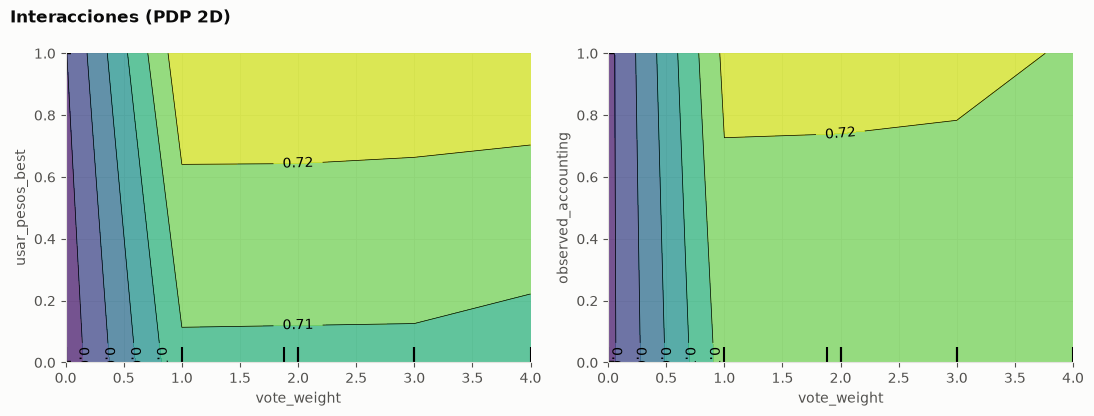

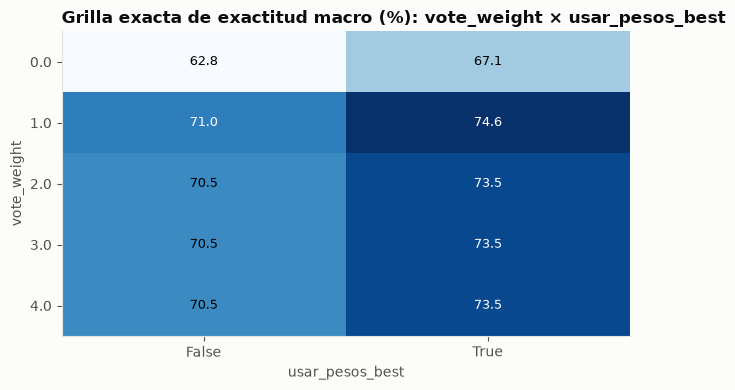

Variación del efecto de usar_pesos_best según vote_weight (desv. estándar del rango por fila): 0.54 pp. Cerca de 0 = poca interacción.


In [12]:
top = [p for p in importancia.index if X[p].nunique() > 1][:3]
pares = [(top[0], top[1]), (top[0], top[2])]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
try:
    PartialDependenceDisplay.from_estimator(sustituto, X, pares, ax=ax, grid_resolution=8)
    fig.suptitle('Interacciones (PDP 2D)', x=.01, ha='left', fontweight='bold')
    plt.tight_layout(); fig.savefig(FIG / 'interacciones_pdp2d.png', dpi=150); plt.show()
except ValueError as exc:   # superficie plana: todas las configuraciones dieron la misma exactitud
    plt.close(fig); print('PDP 2D no disponible:', exc)

a, b = top[0], top[1]
grilla = pd.DataFrame([{a: str(va), b: str(vb), 'exactitud': objetivo(dict(DEFECTO, **{a: va, b: vb}), opt)['exactitud_macro']}
                       for va in ESPACIO[a] for vb in ESPACIO[b]])
tabla = grilla.pivot(index=a, columns=b, values='exactitud').mul(100)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.imshow(tabla.values, cmap='Blues', aspect='auto'); ax.grid(False)
ax.set_xticks(range(tabla.shape[1]), [str(c) for c in tabla.columns]); ax.set_yticks(range(tabla.shape[0]), [str(c) for c in tabla.index])
ax.set_xlabel(b); ax.set_ylabel(a)
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        ax.text(j, i, f'{tabla.values[i, j]:.1f}', ha='center', va='center', fontsize=9,
                color='white' if tabla.values[i, j] > np.nanmean(tabla.values) else 'black')
ax.set_title(f'Grilla exacta de exactitud macro (%): {a} × {b}', loc='left')
plt.tight_layout(); fig.savefig(FIG / 'interaccion_grilla.png', dpi=150); plt.show()
interaccion = (tabla.max(axis=1) - tabla.min(axis=1)).std()
print(f'Variación del efecto de {b} según {a} (desv. estándar del rango por fila): {interaccion:.2f} pp. Cerca de 0 = poca interacción.')

## 10. Configuración seleccionada
Regla: mayor exactitud macro en la muestra de optimización; ante empate, mejor peor-campo, mayor exactitud global, menos cambios respecto a la configuración actual y menor costo de OCR.

,actual,seleccionada,cambia
primary_weight,1.5,2.0,True
vote_weight,2.0,2.0,False
fuzzy_weight,0.5,1.0,True
balance_bonus,3.0,0.0,True
printed_improvements,True,True,False
semantic_amounts,True,False,True
document_consistency,True,True,False
structured_fields,True,False,True
observed_accounting,True,True,False
confidence_rescue,True,True,False


Optimización: actual 73.5% → seleccionada 74.4% (macro); 11.6 s → 10.5 s de OCR por documento


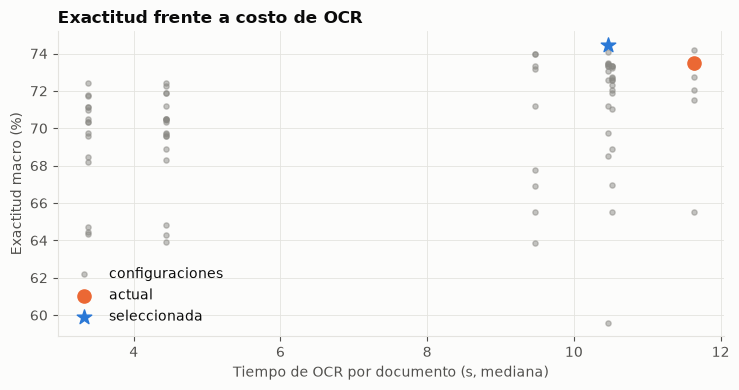

In [13]:
orden = busqueda.sort_values(['exactitud_macro', 'peor_campo', 'exactitud_global', 'cambios', 'segundos_ocr'],
                             ascending=[False, False, False, True, True])
mejor_fila = orden.iloc[0]
MEJOR = {p: (mejor_fila[p].item() if hasattr(mejor_fila[p], 'item') else mejor_fila[p]) for p in PARAMS}
comparacion = pd.DataFrame({'actual': DEFECTO, 'seleccionada': MEJOR}).loc[PARAMS]
comparacion['cambia'] = comparacion.actual.astype(str) != comparacion.seleccionada.astype(str)
display(comparacion)
print(f"Optimización: actual {BASE['exactitud_macro']:.1%} → seleccionada {mejor_fila.exactitud_macro:.1%} (macro); "
      f"{BASE['segundos_ocr']:.1f} s → {mejor_fila.segundos_ocr:.1f} s de OCR por documento")
fig, ax = plt.subplots(figsize=(7.5, 4))
ax.scatter(busqueda.segundos_ocr, 100 * busqueda.exactitud_macro, s=14, alpha=.5, color=F.GRIS, label='configuraciones')
ax.scatter([BASE['segundos_ocr']], [100 * BASE['exactitud_macro']], s=90, color=F.NARANJA, label='actual', zorder=3)
ax.scatter([mejor_fila.segundos_ocr], [100 * mejor_fila.exactitud_macro], s=120, color=F.AZUL, marker='*', label='seleccionada', zorder=3)
ax.set_xlabel('Tiempo de OCR por documento (s, mediana)'); ax.set_ylabel('Exactitud macro (%)')
ax.set_title('Exactitud frente a costo de OCR', loc='left'); ax.legend()
plt.tight_layout(); fig.savefig(FIG / 'exactitud_vs_costo.png', dpi=150); plt.show()

## 11. Antes / después en la muestra de control
La configuración se eligió mirando la muestra de optimización, así que su exactitud allí está inflada. La comparación justa es en la muestra de **control**, que no se usó para elegir. Se usa `evaluation.evaluate` y el bootstrap pareado del repositorio.

**Regla de decisión (fijada antes de ver el resultado):** adoptar la configuración seleccionada solo si mejora en control, el límite inferior del intervalo de confianza al 95 % es mayor que 0 y no empeora el peor campo. Si no, se mantiene la configuración actual.

In [14]:
def evaluar_en(hp, filas, carpeta):
    pred = predecir(hp, filas)
    lista = [{'id': f['id'], 'dataset': f['dataset'], 'fields': pred[f['id']]['fields'], 'status': pred[f['id']]['status'],
              'text': '', 'elapsed_seconds': None, 'cache_hit': True} for f in filas]
    return evaluate(filas, lista, CONFIG, carpeta / 'evaluation', calculate_cer=False)

antes = evaluar_en(DEFECTO, control, OPT / 'control_actual')
despues = evaluar_en(MEJOR, control, OPT / 'control_seleccionada')
delta = bootstrap_delta(OPT / 'control_actual', OPT / 'control_seleccionada')
obj_antes, obj_despues = objetivo(DEFECTO, control), objetivo(MEJOR, control)
tabla_ad = pd.DataFrame({'optimización · macro': [BASE['exactitud_macro'], mejor_fila.exactitud_macro],
                         'control · macro': [obj_antes['exactitud_macro'], obj_despues['exactitud_macro']],
                         'control · global': [antes['micro_exact_match'], despues['micro_exact_match']],
                         'control · peor campo': [obj_antes['peor_campo'], obj_despues['peor_campo']]},
                        index=['actual (definitivo.json)', 'seleccionada']).mul(100).round(2)
display(tabla_ad)
display(pd.DataFrame([delta]).round(2))
m_a = pd.read_csv(OPT / 'control_actual/evaluation/metrics.csv'); m_s = pd.read_csv(OPT / 'control_seleccionada/evaluation/metrics.csv')
por_campo = m_a[m_a.support > 0][['dataset', 'field', 'support', 'exact_match']].merge(
    m_s[['dataset', 'field', 'exact_match']], on=['dataset', 'field'], suffixes=('_actual', '_seleccionada'))
display(por_campo.assign(exact_match_actual=lambda d: (100 * d.exact_match_actual).round(1),
                         exact_match_seleccionada=lambda d: (100 * d.exact_match_seleccionada).round(1)))
ADOPTAR = MEJOR != DEFECTO and delta['delta_pp'] > 0 and delta['ic95_inferior_pp'] > 0 and obj_despues['peor_campo'] >= obj_antes['peor_campo']
print('DECISIÓN:', 'adoptar la configuración seleccionada' if ADOPTAR else 'mantener la configuración actual (la mejora no es consistente en control)')

,optimización · macro,control · macro,control · global,control · peor campo
actual (definitivo.json),73.50,75.45,77.55,57.14
seleccionada,74.44,72.65,74.49,57.14


,delta_pp,ic95_inferior_pp,ic95_superior_pp,nota
0,-3.06,-7.07,0.0,"Bootstrap pareado por documento, estratificado..."


,dataset,field,support,exact_match_actual,exact_match_seleccionada
0,sroie,date,20,90.0,85.0
1,sroie,total,19,89.5,89.5
2,wildreceipt,date,16,81.2,81.2
3,wildreceipt,subtotal,14,57.1,57.1
4,wildreceipt,tax,12,58.3,58.3
5,wildreceipt,total,17,76.5,64.7
6,ALL,date,36,86.1,83.3
7,ALL,subtotal,14,57.1,57.1
8,ALL,tax,12,58.3,58.3
9,ALL,total,36,83.3,77.8


DECISIÓN: mantener la configuración actual (la mejora no es consistente en control)


## 12. Guardar resultados
`configuracion_recomendada.json` es lo que puede cargar `05_evaluacion.ipynb` (opción `USAR_CONFIG_OPTIMIZADA`). Se guarda **antes** de ver el test. El ZIP reúne las tablas y figuras de la optimización (en el repositorio, en `results/metrics/optimizacion/` y `results/figures/optimizacion/`).

In [15]:
RECOMENDADA = MEJOR if ADOPTAR else DEFECTO
recomendada = {'consensus_parameters': {k: float(RECOMENDADA[k]) for k in PARAMS_CONSENSO},
               'etapas': {e: bool(RECOMENDADA[e]) for e in ETAPAS_BUSQUEDA},
               'vistas': {v: bool(RECOMENDADA[v]) for v in VISTAS_BUSQUEDA},
               'decision': 'adoptar' if ADOPTAR else 'mantener_actual'}
seleccion = {'fecha_utc': __import__('datetime').datetime.now(__import__('datetime').timezone.utc).isoformat(),
             'revision_codigo': REVISION, 'semilla': SEED,
             'muestras': {'optimizacion': [r['id'] for r in opt], 'control': [r['id'] for r in control]},
             'espacio': {k: [str(x) for x in v] for k, v in ESPACIO.items()}, 'n_busqueda': len(busqueda),
             'actual': DEFECTO, 'seleccionada': MEJOR, 'r2_oob_sustituto': R2_OOB,
             'optimizacion': {'actual': BASE['exactitud_macro'], 'seleccionada': float(mejor_fila.exactitud_macro)},
             'control': {'actual': obj_antes, 'seleccionada': obj_despues, **delta},
             'importancia': importancia['permutación'].round(5).to_dict(), 'recomendada': recomendada}
(OPT / 'seleccion.json').write_text(json.dumps(seleccion, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
(OPT / 'configuracion_recomendada.json').write_text(json.dumps(recomendada, ensure_ascii=False, indent=2), encoding='utf-8')
archivo = SALIDAS / 'optimizacion_resultados.zip'
with zipfile.ZipFile(archivo, 'w', zipfile.ZIP_DEFLATED) as z:
    for p in OPT.rglob('*'):
        if p.is_file() and p.name != 'predictions.jsonl' and p.suffix in ('.csv', '.json', '.png'):
            z.write(p, p.relative_to(OPT))
print('Guardado:', OPT / 'configuracion_recomendada.json', '\nZIP:', archivo)
try:
    from google.colab import files
    files.download(str(archivo))
except ImportError:
    pass

Guardado: /home/runner/work/Document-Scanner/Document-Scanner/outputs/experimentos/notebooks/optimizacion/configuracion_recomendada.json 
ZIP: /home/runner/work/Document-Scanner/Document-Scanner/outputs/experimentos/notebooks/optimizacion_resultados.zip


## 13. Conclusiones
- La sensibilidad (sección 5), los PDP (7), el ranking de importancia (8) y las interacciones (9) muestran qué hiperparámetros mueven la exactitud y cómo se combinan.
- La configuración seleccionada (10) solo se adopta si mejora en la muestra de **control** (11) según la regla fijada antes de ver el resultado.
- El análisis completo está en [`docs/optimizacion.md`](../docs/optimizacion.md).

Limitaciones: la muestra es pequeña (decenas de documentos por dataset), así que diferencias de 1–2 puntos pueden ser ruido; por eso la decisión depende del intervalo de confianza en control y no de la mejor cifra en optimización. Apagar vistas se simula sobre lecturas ya hechas; el rescate adaptativo real podría activarse distinto con menos vistas.